# Seminar 3: convolutions, from LeNet to ConvNeXt

From LeNet (1998) to ConvNeXt (2022), almost every new CNN is the same few parts
rearranged: the 1×1 conv, `groups=`, the skip connection and the
normalization layer. This notebook builds those parts, **measures** them, and ends by
replaying the ConvNeXt paper on CIFAR-10. In 2021 transformers beat CNNs on ImageNet, and
ConvNeXt asked: *was it attention, or everything around it?*

1. **A convolution is a matrix multiply.** `conv2d` from scratch, 1×1 convs and groups.
2. **Receptive fields, measured.** What one output pixel actually sees.
3. **Global pooling.** Fewer weights, and any input size.
4. **Batch norm's sharp edges.** Four bugs that raise no error, and the LayerNorm fix.
5. **Why residuals work, measured.** Gradients and training curves, plain vs residual.
6. **The ConvNeXt ladder.** ResNet → ConvNeXt, one change at a time, on CIFAR-10.
7. **Try it.**

Sections 1 and 2 run on a laptop CPU in seconds. Sections 3 to 5 train small networks: a
few minutes on a GPU or Apple silicon. Section 6 trains seven networks and is meant for a
GPU (Snellius or Colab); on a laptop it falls back to a short run. The number of epochs is a
constant at the top of each section.

In [11]:
import copy
import math
import time
from collections.abc import Callable, Iterator
from dataclasses import dataclass, replace
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import Tensor, nn
from torch.utils.flop_counter import FlopCounterMode

torch.manual_seed(0)
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():  # Apple silicon
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
DATA = Path("../data") if Path("../train.py").exists() else Path("data")  # repo root or Colab
print("device:", DEVICE)

device: mps


## 0. Data, a training loop, and a counter

CIFAR-10 from the Hugging Face Hub, with the same 45,000 / 5,000 split as notebook 1. One
change: the whole dataset is **one `uint8` tensor on the GPU** (150 MB), and augmentation
(random crop and flip) runs on whole batches there. No `DataLoader`, no worker processes.
For 32×32 images this is several times faster than decoding PIL images one at a time.
It only works because CIFAR fits in memory; for ImageNet you go back to notebook 1's
`DataLoader`.

In [12]:
MEAN = torch.tensor((0.4914, 0.4822, 0.4465), device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor((0.2470, 0.2435, 0.2616), device=DEVICE).view(1, 3, 1, 1)

cifar = datasets.load_dataset("uoft-cs/cifar10", cache_dir=str(DATA))


def to_tensors(split: datasets.Dataset) -> tuple[Tensor, Tensor]:
    """A split as (N, 3, 32, 32) uint8 images and (N,) labels, on DEVICE."""
    split = split.with_format("numpy")[:]  # every row at once, as a dict of numpy arrays
    x = torch.from_numpy(np.stack(split["img"])).permute(0, 3, 1, 2).contiguous()
    y = torch.from_numpy(split["label"]).long()
    return x.to(DEVICE), y.to(DEVICE)


x_all, y_all = to_tensors(cifar["train"])
x_test, y_test = to_tensors(cifar["test"])
perm = torch.randperm(len(x_all), generator=torch.Generator().manual_seed(0)).to(DEVICE)
x_val, y_val = x_all[perm[:5000]], y_all[perm[:5000]]
x_train, y_train = x_all[perm[5000:]], y_all[perm[5000:]]
print(f"train {tuple(x_train.shape)} | val {tuple(x_val.shape)} | test {tuple(x_test.shape)}")


def normalize(x: Tensor) -> Tensor:
    """uint8 images -> floats with mean 0 and std 1 per channel."""
    return (x.float() / 255 - MEAN) / STD


def augment(x: Tensor) -> Tensor:
    """Random 32×32 crop of the image padded by 4 pixels, and a random horizontal flip."""
    n = x.shape[0]
    padded = F.pad(x, (4, 4, 4, 4))
    i = torch.randint(0, 9, (n, 1, 1), device=x.device) + torch.arange(32, device=x.device).view(
        1, 32, 1
    )
    j = torch.randint(0, 9, (n, 1, 1), device=x.device) + torch.arange(32, device=x.device).view(
        1, 1, 32
    )
    batch = torch.arange(n, device=x.device).view(n, 1, 1)
    x = padded.permute(0, 2, 3, 1)[batch, i, j].permute(0, 3, 1, 2)  # (N, 3, 32, 32)
    flip = torch.rand(n, 1, 1, 1, device=x.device) < 0.5
    return torch.where(flip, x.flip(3), x)


def batches(
    x: Tensor, y: Tensor, batch_size: int, train: bool = False
) -> Iterator[tuple[Tensor, Tensor]]:
    """Normalized batches; shuffled and augmented when training."""
    order = torch.randperm(len(x), device=x.device) if train else torch.arange(len(x))
    for start in range(0, len(x), batch_size):
        idx = order[start : start + batch_size]
        xb = normalize(x[idx])
        yield (augment(xb) if train else xb), y[idx]


@torch.no_grad()
def accuracy(model: nn.Module, x: Tensor = x_val, y: Tensor = y_val, bs: int = 1000) -> float:
    """Accuracy in eval mode, in percent."""
    model.eval()
    correct = sum((model(xb).argmax(1) == yb).sum().item() for xb, yb in batches(x, y, bs))
    return 100 * correct / len(x)


def train(
    model: nn.Module,
    epochs: int,
    lr: float = 2e-3,
    weight_decay: float = 0.05,
    batch_size: int = 256,
    label_smoothing: float = 0.1,
    verbose: bool = True,
) -> dict:
    """AdamW with a one-cycle schedule; the same recipe for every model in this notebook."""
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps = epochs * math.ceil(len(x_train) / batch_size)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.15)
    hist: dict[str, list] = {"loss": [], "val_acc": []}
    start = time.time()
    for epoch in range(epochs):
        model.train()
        for xb, yb in batches(x_train, y_train, batch_size, train=True):
            loss = F.cross_entropy(model(xb), yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            hist["loss"].append(loss.item())
        hist["val_acc"].append(accuracy(model))
        if verbose:
            print(
                f"epoch {epoch + 1:>2}/{epochs}  loss {np.mean(hist['loss'][-50:]):.3f}  "
                f"val {hist['val_acc'][-1]:.1f}%  ({time.time() - start:.0f}s)"
            )
    hist["seconds"] = time.time() - start
    return hist

train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | test (10000, 3, 32, 32)


And a counter for the two numbers every architecture paper quotes: **weights** and
**mult-adds**. `FlopCounterMode` ships with PyTorch. It counts the FLOPs of every
convolution and matmul in one forward pass. A mult-add is two FLOPs. Like the papers, it
skips the cheap parts (norms, activations, pooling).

In [13]:
def count(model: nn.Module, shape: tuple[int, ...] = (1, 3, 32, 32)) -> tuple[int, int]:
    """(weights, mult-adds) of one forward pass on an input of `shape`."""
    params = sum(p.numel() for p in model.parameters())
    device = next(model.parameters()).device
    was_training = model.training
    model.eval()
    with FlopCounterMode(display=False) as counter, torch.no_grad():
        model(torch.zeros(shape, device=device))
    model.train(was_training)
    return params, counter.get_total_flops() // 2


def human(n: float) -> str:
    """1234567 -> '1.23M'."""
    for unit, size in (("G", 1e9), ("M", 1e6), ("k", 1e3)):
        if abs(n) >= size:
            return f"{n / size:.3g}{unit}"
    return str(int(n))

## 1. A convolution is a matrix multiply

### 1.1 `conv2d` from scratch

Each output value is the dot product of one filter with one k×k×C_in patch of the input
`F.unfold` (also called *im2col*) cuts out every patch and lays it out as a
column. After that, the whole convolution is **one matrix multiply**: filters as rows,
patches as columns.

In [14]:
def conv2d(
    x: Tensor, weight: Tensor, bias: Tensor | None = None, stride: int = 1, padding: int = 0
) -> Tensor:
    """Our conv: unfold every patch into a column, then one matmul with the filters."""
    n, _, h, w = x.shape
    c_out, _, k, _ = weight.shape
    cols = F.unfold(x, k, padding=padding, stride=stride)  # (N, C_in·k·k, number of patches)
    out = weight.view(c_out, -1) @ cols  # (C_out, C_in·k·k) @ (N, C_in·k·k, L) -> (N, C_out, L)
    if bias is not None:
        out = out + bias.view(1, -1, 1)
    h_out = (h + 2 * padding - k) // stride + 1
    w_out = (w + 2 * padding - k) // stride + 1
    return out.view(n, c_out, h_out, w_out)


x = torch.randn(1, 3, 6, 6)  # a 6 × 6 × 3 input, 4 filters of 3 × 3 × 3
conv = nn.Conv2d(3, 4, kernel_size=3)
print("patches as columns:", tuple(F.unfold(x, 3).shape), "= 16 patches of 3·3·3 = 27 numbers")
print("output:", tuple(conv2d(x, conv.weight, conv.bias).shape))

for stride, padding in ((1, 0), (1, 1), (2, 1)):
    x = torch.randn(2, 16, 15, 15)
    conv = nn.Conv2d(16, 32, 3, stride=stride, padding=padding)
    ours = conv2d(x, conv.weight, conv.bias, stride, padding)
    print(
        f"stride {stride}, padding {padding}: {tuple(ours.shape)}  "
        f"matches nn.Conv2d: {torch.allclose(ours, conv(x), atol=1e-5)}"
    )

patches as columns: (1, 27, 16) = 16 patches of 3·3·3 = 27 numbers
output: (1, 4, 4, 4)
stride 1, padding 0: (2, 32, 13, 13)  matches nn.Conv2d: True
stride 1, padding 1: (2, 32, 15, 15)  matches nn.Conv2d: True
stride 2, padding 1: (2, 32, 8, 8)  matches nn.Conv2d: True


im2col copies every input pixel into up to k² columns, so it costs memory. cuDNN picks
among several algorithms (implicit GEMM, FFT, Winograd), but they all compute what these
eight lines compute.

### 1.2 A 1×1 conv is a dense layer over the channels

At every pixel, a 1×1 conv computes `y = W x` over the channels, with the same `W`
everywhere. So it should be exactly an `nn.Linear` applied to channels-last data. ConvNeXt
relies on this (section 6).

In [15]:
conv1x1 = nn.Conv2d(192, 16, kernel_size=1)
linear = nn.Linear(192, 16)
linear.weight.data = conv1x1.weight.data.view(16, 192)  # same numbers, (16, 192, 1, 1) -> (16, 192)
linear.bias.data = conv1x1.bias.data

x = torch.randn(2, 192, 28, 28)
via_linear = linear(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)  # (N, H, W, C) in and out
print("1×1 conv == Linear over channels:", torch.allclose(conv1x1(x), via_linear, atol=1e-5))

1×1 conv == Linear over channels: True


### 1.3 Groups

`groups=G` splits the input channels into G groups. Each filter sees only its own group
We can write that with the `conv2d` above: split, convolve each part, concatenate.

In [16]:
def grouped_conv2d(x: Tensor, weight: Tensor, groups: int, padding: int = 0) -> Tensor:
    """G independent convolutions, each on C_in / G channels, outputs concatenated."""
    xs = x.chunk(groups, dim=1)  # G inputs of C_in / G channels
    ws = weight.chunk(groups, dim=0)  # G sets of C_out / G filters, each C_in / G deep
    return torch.cat([conv2d(xg, wg, padding=padding) for xg, wg in zip(xs, ws, strict=True)], 1)


x = torch.randn(2, 128, 8, 8)
print(f"{'groups':>8} {'weight shape':>18} {'weights':>9}  matches")
for g in (1, 2, 32, 128):
    conv = nn.Conv2d(128, 128, 3, padding=1, groups=g, bias=False)
    ok = torch.allclose(grouped_conv2d(x, conv.weight, g, padding=1), conv(x), atol=1e-4)
    print(f"{g:>8} {str(tuple(conv.weight.shape)):>18} {conv.weight.numel():>9,}  {ok}")

  groups       weight shape   weights  matches
       1   (128, 128, 3, 3)   147,456  True
       2    (128, 64, 3, 3)    73,728  True
      32     (128, 4, 3, 3)     4,608  True
     128     (128, 1, 3, 3)     1,152  True


`groups=C` is the **depthwise** conv: every filter is 3×3×1.

## 2. Receptive fields, measured

Which input pixels can change one output pixel? Autograd answers that directly: take the
gradient of the centre output pixel with respect to the input. A pixel the output can't see
gets a gradient of exactly zero.

Theory: n stacked 3×3 convs see a (2n+1)×(2n+1) patch. We average the gradient
map over a few random initializations.

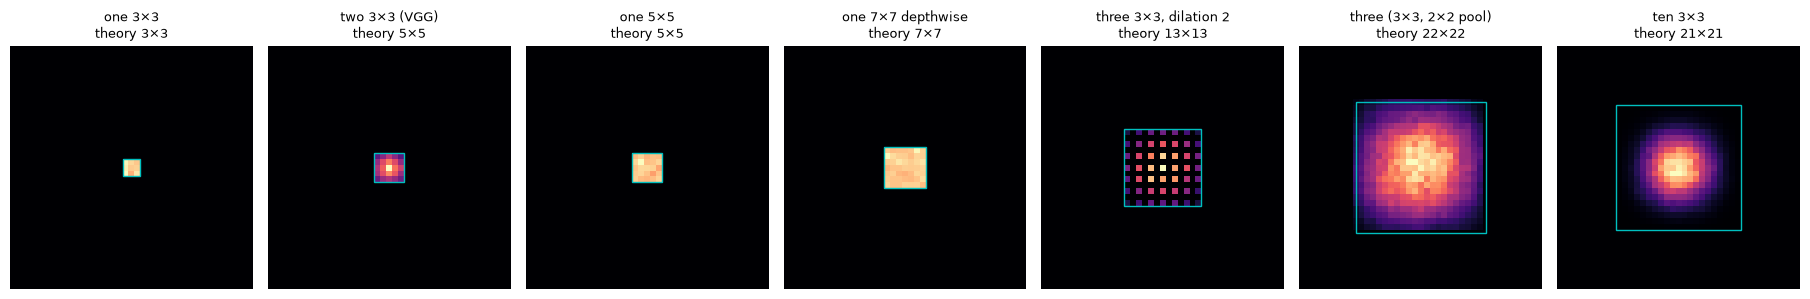

In [17]:
def rf_map(make_net: Callable[[], nn.Module], size: int = 41, trials: int = 16) -> Tensor:
    """|d centre output / d input|, summed over channels, averaged over random inits."""
    total = torch.zeros(size, size)
    for _ in range(trials):
        x = torch.randn(1, 16, size, size, requires_grad=True)
        y = make_net()(x)
        y[0, :, y.shape[2] // 2, y.shape[3] // 2].sum().backward()
        total += x.grad[0].abs().sum(0)
    return total / trials


def stack(n: int, k: int = 3, dilation: int = 1, pool: bool = False) -> Callable[[], nn.Module]:
    """A factory for n layers of (conv k×k, ReLU), 16 channels, each optionally pooled."""

    def make() -> nn.Module:
        layers: list[nn.Module] = []
        for _ in range(n):
            pad = dilation * (k // 2)
            layers += [nn.Conv2d(16, 16, k, padding=pad, dilation=dilation), nn.ReLU()]
            if pool:
                layers.append(nn.MaxPool2d(2))
        return nn.Sequential(*layers)

    return make


def depthwise(k: int) -> Callable[[], nn.Module]:
    """A factory for one depthwise k×k conv."""
    return lambda: nn.Conv2d(16, 16, k, padding=k // 2, groups=16)


nets = {
    "one 3×3": (stack(1), 3),
    "two 3×3 (VGG)": (stack(2), 5),
    "one 5×5": (stack(1, k=5), 5),
    "one 7×7 depthwise": (depthwise(7), 7),
    "three 3×3, dilation 2": (stack(3, dilation=2), 13),
    "three (3×3, 2×2 pool)": (stack(3, pool=True), 22),
    "ten 3×3": (stack(10), 21),
}
fig, axes = plt.subplots(1, len(nets), figsize=(2.6 * len(nets), 3))
for ax, (name, (make, theory)) in zip(axes, nets.items(), strict=True):
    m = rf_map(make)
    ax.imshow(m, cmap="magma")
    c = m.shape[0] // 2
    ax.add_patch(
        plt.Rectangle((c - theory / 2, c - theory / 2), theory, theory, fill=False, ec="c", lw=1)
    )
    ax.set_title(f"{name}\ntheory {theory}×{theory}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

The cyan box is the theoretical receptive field. The first five fill their box. Dilation
leaves holes: a 3×3 conv with dilation 2 sees a 5×5 area but only 9 pixels of it. Pooling
makes the receptive field grow fast. And **ten 3×3 layers don't really see 21×21**: the
gradient is bright in the middle and fades towards the edge.

This is the **effective receptive field** (Luo et al., 2016). A centre pixel reaches the
output along many more paths than an edge pixel, so its influence is much larger. Let's
measure how wide that bright region is as we add layers.

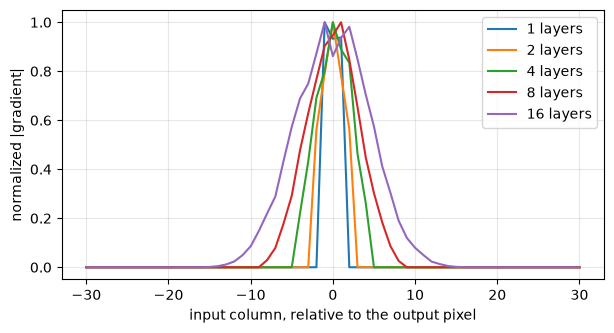

 1 layers of 3×3: theory  3 pixels wide, effective ≈  1.6
 2 layers of 3×3: theory  5 pixels wide, effective ≈  2.6
 4 layers of 3×3: theory  9 pixels wide, effective ≈  4.1
 8 layers of 3×3: theory 17 pixels wide, effective ≈  6.2
16 layers of 3×3: theory 33 pixels wide, effective ≈  8.9


In [18]:
depths = (1, 2, 4, 8, 16)
theory, effective = [], []
fig, ax = plt.subplots(figsize=(7, 3.5))
for n in depths:
    profile = rf_map(stack(n), size=61)[30]  # the centre row
    profile = profile / profile.sum()
    pos = torch.arange(61) - 30.0
    effective.append(2 * (profile * pos**2).sum().sqrt().item())  # 2 standard deviations wide
    theory.append(2 * n + 1)
    ax.plot(pos, profile / profile.max(), label=f"{n} layers")
ax.set_xlabel("input column, relative to the output pixel")
ax.set_ylabel("normalized |gradient|")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
for n, t, e in zip(depths, theory, effective, strict=True):
    print(f"{n:>2} layers of 3×3: theory {t:>2} pixels wide, effective ≈ {e:4.1f}")

The theoretical width grows like **n**, the effective width only like **√n**: 16 layers
of 3×3 see 33 pixels on paper, but most of the signal comes from the middle third. That's
why every CNN **downsamples** (pools or strides) between stages. It's also part of why
ConvNeXt moves to 7×7 kernels: it gets a bigger view per layer, and a
depthwise 7×7 costs only 49·C weights.

## 3. Global pooling

Now we need a trained network: a small CNN like notebook 1's, which pools twice, so the last
feature map is 8×8×128. Its head is the one from Network in Network: a global average pool,
then one linear layer. We reuse this network in section 4.

In [19]:
EPOCHS_SMALL = 8  # about a minute on a GPU or Apple silicon


def conv_bn_relu(c_in: int, c_out: int, stride: int = 1) -> list[nn.Module]:
    """3×3 conv (no bias: the BN right after it has one), batch norm, ReLU."""
    conv = nn.Conv2d(c_in, c_out, 3, stride, padding=1, bias=False)
    return [conv, nn.BatchNorm2d(c_out), nn.ReLU()]


class GapCNN(nn.Module):
    """(B, 3, H, W) -> features (B, 4w, H/4, W/4) -> global average pool -> (B, 10) logits."""

    def __init__(self, w: int = 32) -> None:
        """Three stages of two conv-BN-ReLU, with a 2×2 max-pool between them."""
        super().__init__()
        self.features = nn.Sequential(
            *conv_bn_relu(3, w), *conv_bn_relu(w, w), nn.MaxPool2d(2),
            *conv_bn_relu(w, 2 * w), *conv_bn_relu(2 * w, 2 * w), nn.MaxPool2d(2),
            *conv_bn_relu(2 * w, 4 * w), *conv_bn_relu(4 * w, 4 * w),
        )  # fmt: skip
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(4 * w, 10)

    def forward(self, x: Tensor) -> Tensor:
        """Features, average over every position, then a linear classifier."""
        return self.fc(self.pool(self.features(x)).flatten(1))


torch.manual_seed(0)
gap_cnn = GapCNN()
params, macs = count(gap_cnn)
print(f"GapCNN: {human(params)} weights, {human(macs)} mult-adds per image")
gap_hist = train(gap_cnn, EPOCHS_SMALL)
print(f"test accuracy: {accuracy(gap_cnn, x_test, y_test):.1f}%")

GapCNN: 289k weights, 38.6M mult-adds per image
epoch  1/8  loss 1.511  val 55.6%  (5s)
epoch  2/8  loss 1.261  val 63.7%  (10s)
epoch  3/8  loss 1.138  val 65.1%  (16s)
epoch  4/8  loss 1.046  val 71.7%  (21s)
epoch  5/8  loss 0.987  val 78.7%  (26s)
epoch  6/8  loss 0.943  val 81.3%  (31s)
epoch  7/8  loss 0.913  val 83.5%  (36s)
epoch  8/8  loss 0.888  val 83.7%  (42s)
test accuracy: 83.7%


Global pooling turns any H × W map into one C-dimensional vector. Compare with the
LeNet/AlexNet head, which flattens the map into a dense layer.

In [20]:
flatten_head = nn.Linear(128 * 8 * 8, 10)  # what a "flatten, then dense" head on 8×8×128 needs
gap_weights = sum(p.numel() for p in gap_cnn.fc.parameters())
flat_weights = sum(p.numel() for p in flatten_head.parameters())
print(f"head weights: global pool + linear {gap_weights:,}, flatten + linear {flat_weights:,}")

gap_cnn.eval()
for h, w in ((32, 32), (64, 48), (96, 160)):
    x = torch.randn(1, 3, h, w, device=DEVICE)
    feats = gap_cnn.features(x)
    print(
        f"input {h:>3}×{w:<3} -> features {tuple(feats.shape)} -> logits {tuple(gap_cnn(x).shape)}"
    )
    try:
        flatten_head.to(DEVICE)(feats.flatten(1))
    except RuntimeError as e:
        print("   flatten + linear:", str(e).split("\n")[0])

head weights: global pool + linear 1,290, flatten + linear 81,930
input  32×32  -> features (1, 128, 8, 8) -> logits (1, 10)
input  64×48  -> features (1, 128, 16, 12) -> logits (1, 10)
   flatten + linear: linear(): input and weight.T shapes cannot be multiplied (1x24576 and 8192x10)
input  96×160 -> features (1, 128, 24, 40) -> logits (1, 10)
   flatten + linear: linear(): input and weight.T shapes cannot be multiplied (1x122880 and 8192x10)


The global-pool head has 63× fewer weights, and the same network classifies an image of any
size. That fixed-length vector is what lets a CNN act as a general image encoder.

## 4. Batch norm's sharp edges

Batch norm is in nearly every CNN before ConvNeXt, and every bug below
**runs without an error**. You only see a worse number.

### 4.1 What it computes, by hand

In [21]:
bn = nn.BatchNorm2d(64)
x = 3 * torch.randn(8, 64, 14, 14) + 2
mu = x.mean(dim=(0, 2, 3), keepdim=True)  # one mean per channel, over N × H × W
var = x.var(dim=(0, 2, 3), keepdim=True, unbiased=False)
by_hand = (x - mu) / torch.sqrt(var + bn.eps)  # γ = 1, β = 0 at init
print("bn(x) == by hand:", torch.allclose(bn(x), by_hand, atol=1e-5))
print(
    "running_mean after one batch == 0.1 · μ:", torch.allclose(bn.running_mean, 0.1 * mu.flatten())
)

bn(x) == by hand: True
running_mean after one batch == 0.1 · μ: True


Note the convention: `momentum=0.1` is the weight of the **new** batch,
`running = 0.9 · running + 0.1 · batch`. That's the opposite of an optimizer's momentum.

### 4.2 Pitfall 1: forgetting `model.eval()`

In train mode, BN normalizes with the statistics of **the current batch**. If you evaluate
in train mode, the results depend on the batch size. Worse, it silently overwrites the
running statistics, **even inside `torch.no_grad()`**.

In [22]:
@torch.no_grad()
def acc_train_mode(model: nn.Module, bs: int) -> float:
    """Validation accuracy with the model left in train mode (the bug)."""
    model.train()
    correct = sum((model(xb).argmax(1) == yb).sum().item() for xb, yb in batches(x_val, y_val, bs))
    return 100 * correct / len(x_val)


net = copy.deepcopy(gap_cnn)
print(f"eval mode:                   {accuracy(net):.1f}%")
for bs in (1000, 32, 4):
    print(f"train mode, batch size {bs:>4}: {acc_train_mode(net, bs):.1f}%")
print(f"eval mode again:             {accuracy(net):.1f}%   <- the running stats were overwritten")

eval mode:                   83.7%
train mode, batch size 1000: 83.8%
train mode, batch size   32: 82.3%
train mode, batch size    4: 70.0%
eval mode again:             83.0%   <- the running stats were overwritten


Lightning calls `model.eval()` for you in `validation_step`. In a hand-written loop like
notebook 1's, it is your job. And remember to call `model.train()` again afterwards.

### 4.3 Pitfall 2: in train mode, one image's prediction depends on its batch

Classify 200 test images twice: each one in a batch with 15 random images, then in a batch
with 15 trucks. The image and the network are the same both times. Only the company
changes.

In [23]:
images = normalize(x_test[y_test != 9][:200])
randoms = normalize(x_test[-15:])
trucks = normalize(x_test[y_test == 9][:15])
net = copy.deepcopy(gap_cnn)
with torch.no_grad():
    for mode in ("train", "eval"):
        net.train(mode == "train")
        flips = sum(
            net(torch.cat([img[None], randoms]))[0].argmax()
            != net(torch.cat([img[None], trucks]))[0].argmax()
            for img in images
        ).item()
        print(f"{mode:>5} mode: {flips:>3} of 200 predictions change")

train mode:  57 of 200 predictions change
 eval mode:   0 of 200 predictions change


In train mode, the batch acts as part of the input. This matters when batches are not
random: one class per batch, sorted data, or one video's frames in a batch.

### 4.4 Pitfall 3: batch size 1

After global pooling there is one value per channel per image. With one image in the
batch, the variance is undefined. This one, at least, raises an error.

In [24]:
head_bn = nn.BatchNorm1d(128).train()
try:
    head_bn(torch.randn(1, 128))
except ValueError as e:
    print("ValueError:", e)

ValueError: Expected more than 1 value per channel when training, got input size torch.Size([1, 128])


With feature *maps* (`BatchNorm2d`, H × W > 1), batch size 1 runs without error, but each
image is normalized only by its own statistics. Detection and segmentation models train
with 1–2 large images per GPU, which is why they freeze BN or replace it.

### 4.5 Pitfall 4: a bias right before batch norm is wasted

BN subtracts the per-channel mean, which removes any per-channel constant, including the
conv's bias. Its gradient is zero. That's why every conv in this notebook (and in
notebook 1) has `bias=False` when a BN follows.

In [25]:
layer = nn.Sequential(nn.Conv2d(3, 16, 3, bias=True), nn.BatchNorm2d(16))
layer(torch.randn(8, 3, 32, 32)).pow(2).sum().backward()
print(f"|grad| conv weight: {layer[0].weight.grad.norm():.2e}")
print(f"|grad| conv bias:   {layer[0].bias.grad.norm():.2e}   <- zero, up to float rounding")

|grad| conv weight: 3.15e+00
|grad| conv bias:   7.25e-04   <- zero, up to float rounding


### 4.6 The fix: LayerNorm over the channels

ConvNeXt replaces BN with LayerNorm over the C channels **of each pixel**. It
never looks at other images, so there is no train/eval difference and no batch-size
dependence. PyTorch's `nn.LayerNorm` normalizes the *last* dimension, so we permute to
channels-last and back, the same trick as in 1.2.

Careful: `nn.GroupNorm(1, C)` is sometimes called "LayerNorm for images", but it normalizes
over C × H × W together. **That's a different layer.**

In [26]:
class LayerNorm2d(nn.LayerNorm):
    """LayerNorm over the channels of each pixel of a (N, C, H, W) tensor, as in ConvNeXt."""

    def forward(self, x: Tensor) -> Tensor:
        """Channels-last, normalize, channels-first."""
        return super().forward(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)


x = torch.randn(4, 64, 8, 8)
ln, gn = LayerNorm2d(64), nn.GroupNorm(1, 64)
print("per-pixel mean after LN:", ln(x).mean(dim=1).abs().max().item())
print("LayerNorm2d == GroupNorm(1, C):", torch.allclose(ln(x), gn(x), atol=1e-4))
print("LN of image 0 alone == LN of image 0 in a batch:", torch.allclose(ln(x[:1]), ln(x)[:1]))

per-pixel mean after LN: 5.21540641784668e-08
LayerNorm2d == GroupNorm(1, C): False
LN of image 0 alone == LN of image 0 in a batch: True


## 5. Why residuals work, measured

The CIFAR ResNets of the ResNet paper: three stages of 16, 32 and 64 channels, n basic
blocks each, so 6n + 2 layers. The *plain* version is the same network with the skip
connections removed. Everything else is equal, BN included.

In [27]:
EPOCHS_RES = 4  # per network; four networks


class BasicBlock(nn.Module):
    """conv-BN-ReLU-conv-BN, plus the input if `skip`, then ReLU."""

    def __init__(self, c_in: int, c_out: int, stride: int, skip: bool) -> None:
        """When the shape changes, the skip is a strided 1×1 conv, as in the paper's option B."""
        super().__init__()
        self.f = nn.Sequential(
            *conv_bn_relu(c_in, c_out, stride),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False),
            nn.BatchNorm2d(c_out),
        )
        self.skip = skip
        self.proj = (
            nn.Identity()
            if stride == 1 and c_in == c_out
            else nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm2d(c_out))
        )

    def forward(self, x: Tensor) -> Tensor:
        """Return relu(F(x) + x), or relu(F(x)) without the skip."""
        out = self.f(x)
        return F.relu(out + self.proj(x) if self.skip else out)


def cifar_resnet(n: int, skip: bool = True) -> nn.Sequential:
    """6n + 2 layers: a 3×3 stem, 3 stages of n blocks (16, 32, 64 channels), pool, linear."""
    layers: list[nn.Module] = conv_bn_relu(3, 16)
    c_in = 16
    for i, c in enumerate((16, 32, 64)):
        for j in range(n):
            layers.append(BasicBlock(c_in, c, stride=2 if i > 0 and j == 0 else 1, skip=skip))
            c_in = c
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 10))

### 5.1 The gradient at initialization

One backward pass on one batch, then the gradient norm of every conv in the main path,
from the input to the output.

  plain-20: first conv / last conv gradient = 1.7
  plain-56: first conv / last conv gradient = 2e+02
 ResNet-56: first conv / last conv gradient = 3.4


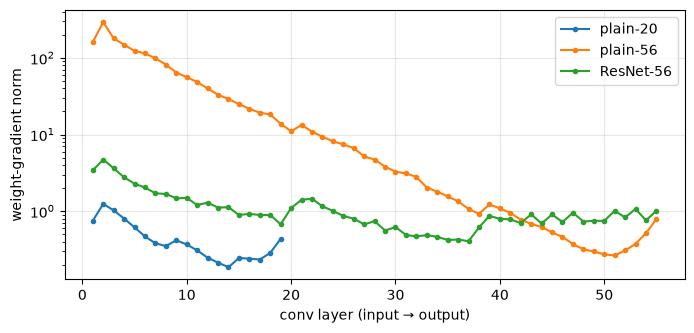

In [28]:
def grad_norms(model: nn.Module) -> list[float]:
    """Weight-gradient norm of each 3×3 conv, input to output, after one batch."""
    model.to(DEVICE).train()
    xb, yb = next(batches(x_train, y_train, 256))
    model.zero_grad()
    F.cross_entropy(model(xb), yb).backward()
    convs = [m for m in model.modules() if isinstance(m, nn.Conv2d) and m.kernel_size == (3, 3)]
    return [m.weight.grad.norm().item() for m in convs]


torch.manual_seed(0)
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, model in {
    "plain-20": cifar_resnet(3, skip=False),
    "plain-56": cifar_resnet(9, skip=False),
    "ResNet-56": cifar_resnet(9),
}.items():
    g = grad_norms(model)
    ax.plot(range(1, len(g) + 1), g, marker=".", label=name)
    print(f"{name:>10}: first conv / last conv gradient = {g[0] / g[-1]:.2g}")
ax.set_yscale("log")
ax.set_xlabel("conv layer (input → output)")
ax.set_ylabel("weight-gradient norm")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

The usual story is that the gradient *vanishes* in deep plain networks. That's what happens without
normalization. **With BN, the plain network's gradient doesn't vanish; it grows towards
the input**, here by two orders of magnitude over 56 layers. The ResNet paper says the
same: its plain networks have BN, and the authors checked that their gradients have
"healthy norms". With the skips, the gradient stays within a factor of a few across all
56 layers.

So if the gradients are fine, why do deep plain networks train badly? Let's look.

### 5.2 The degradation problem

The ResNet paper's key experiment: a deeper plain network has a **higher training loss**
than a shallower one. That's not overfitting; it's an optimization problem. Adding the
skips fixes it. We train all four for a few epochs with the same recipe.

plain-20
   val 68.1%  (33s)
plain-56
   val 37.0%  (86s)
ResNet-20
   val 75.3%  (36s)
ResNet-56
   val 74.5%  (91s)


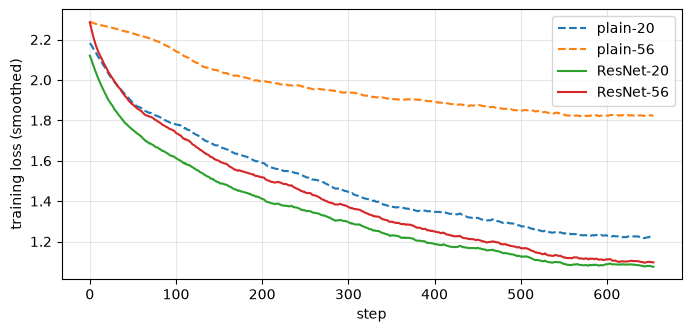

In [29]:
curves = {}
for name, (n, skip) in {
    "plain-20": (3, False),
    "plain-56": (9, False),
    "ResNet-20": (3, True),
    "ResNet-56": (9, True),
}.items():
    torch.manual_seed(0)
    print(name)
    curves[name] = train(cifar_resnet(n, skip), EPOCHS_RES, verbose=False)
    print(f"   val {curves[name]['val_acc'][-1]:.1f}%  ({curves[name]['seconds']:.0f}s)")

fig, ax = plt.subplots(figsize=(8, 3.5))
for name, h in curves.items():
    smooth = np.convolve(h["loss"], np.ones(50) / 50, mode="valid")
    ax.plot(smooth, label=name, ls="-" if "Res" in name else "--")
ax.set_xlabel("step")
ax.set_ylabel("training loss (smoothed)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

The plain-56 curve (dashed orange) sits far above plain-20: after 4 epochs it reaches about
37% validation accuracy against 68% for plain-20. That's on the **training** loss, so it's
not overfitting: the deeper network is worse at fitting the training set, even though it
could copy plain-20 and set its extra layers to the identity. With the skips, both depths
train well (ResNet-20 about 75%, ResNet-56 about 74.5%). In a run this short the extra depth
doesn't pay off yet. That needs the paper's ~160 epochs, but it no longer hurts.

So the problem isn't gradient *size* (5.1). It's that a plain stack of layers has to
*learn* the identity to do no harm, and that's hard. A residual block gets the identity for
free and only learns the change, F(x) = 0 (section 5's block).

## 6. The ConvNeXt ladder

Liu et al. (2022) started from ResNet-50 and changed one thing at a time, each change
borrowed from Swin, until the ResNet had become ConvNeXt. We do the same,
at CIFAR scale. **Every step is a change to one `Spec`**, so the whole ladder is a list of
small diffs.

Changes for 32×32 images:

- **Resolution.** ImageNet stems reduce 224 → 56 (4×). Ours reduce 32 → 16 (2×), so the
  four stages run at 16, 8, 4 and 2 pixels.
- **Depth.** 8 blocks instead of 16–18, and widths chosen so that every step costs
  about the same mult-adds, as in the paper.
- **Training.** Every step uses the same modern recipe (AdamW, one-cycle schedule, label
  smoothing). So the ladder starts *after* the paper's first step, which
  changed only the training.
- **Left out:** layer scale and stochastic depth. Those are exercises.

In [30]:
# Per model, 7 models. 15 epochs take ~1-2 min per model on an A100 and ~5 on Apple silicon;
# on a laptop, 3 epochs show the ranking only roughly. Run the full ladder on a GPU.
LADDER_EPOCHS = 15 if DEVICE.type == "cuda" else 3


@dataclass(frozen=True)
class Spec:
    """Everything that differs between ResNet and ConvNeXt.

    Attributes:
        stem: "conv_pool" (3×3 conv, then 3×3 max-pool with stride 2), or "patchify" (2×2 conv
            with stride 2).
        depths: Blocks per stage.
        widths: Channels between blocks, per stage.
        block: The order of the three convs. "bottleneck": 1×1 down, k×k, 1×1 up. "inverted":
            1×1 up, k×k, 1×1 down. "dw_first": k×k, 1×1 up, 1×1 down.
        depthwise: Whether the k×k conv is depthwise (groups = channels) or full (groups = 1).
        kernel: k.
        act: "relu" or "gelu".
        micro: False: a norm after every conv, an activation after the first two and after the
            add (ResNet). True: one norm after the k×k, one activation after the 1×1 up, and
            nothing after the add (ConvNeXt).
        norm: "bn" (BatchNorm2d) or "ln" (LayerNorm2d).
        downsample: "strided": the first block of each stage has stride 2. "separate": a norm
            and a 2×2 conv with stride 2 between stages.

    """

    stem: str = "conv_pool"
    depths: tuple[int, ...] = (2, 2, 2, 2)
    widths: tuple[int, ...] = (128, 256, 512, 1024)
    block: str = "bottleneck"
    depthwise: bool = False
    kernel: int = 3
    act: str = "relu"
    micro: bool = False
    norm: str = "bn"
    downsample: str = "strided"


def norm_layer(spec: Spec, c: int) -> nn.Module:
    """BatchNorm2d or channels LayerNorm."""
    return nn.BatchNorm2d(c) if spec.norm == "bn" else LayerNorm2d(c)


def act_layer(spec: Spec) -> nn.Module:
    """ReLU or GELU."""
    return nn.ReLU() if spec.act == "relu" else nn.GELU()


class Block(nn.Module):
    """Three convs and a skip. Where the norms and activations go depends on the spec."""

    def __init__(self, spec: Spec, c_in: int, c_out: int, stride: int = 1) -> None:
        """Build the three convs of `spec.block`, with norms and activations in between."""
        super().__init__()
        k = spec.kernel
        # (c_in, c_out, kernel, stride, groups) of the three convs.
        if spec.block == "bottleneck":  # ResNet: squeeze 4×, convolve, expand
            mid = c_out // 4
            groups = mid if spec.depthwise else 1
            convs = [(c_in, mid, 1, 1, 1), (mid, mid, k, stride, groups), (mid, c_out, 1, 1, 1)]
        elif spec.block == "inverted":  # MobileNetV2: expand 4×, convolve, project
            mid = 4 * c_out
            convs = [(c_in, mid, 1, 1, 1), (mid, mid, k, stride, mid), (mid, c_out, 1, 1, 1)]
        else:  # "dw_first", ConvNeXt: convolve, expand 4×, project
            mid = 4 * c_out
            convs = [(c_in, c_in, k, stride, c_in), (c_in, mid, 1, 1, 1), (mid, c_out, 1, 1, 1)]

        if spec.micro:  # ConvNeXt: norm after conv 0, activation after conv 1, nothing after +
            norm_after, act_after, self.act_out = {0}, {1}, nn.Identity()
        else:  # ResNet: norm after every conv, activation after the first two and after the add
            norm_after, act_after, self.act_out = {0, 1, 2}, {0, 1}, act_layer(spec)

        layers: list[nn.Module] = []
        for i, (ci, co, kk, s, g) in enumerate(convs):
            bias = i not in norm_after  # a norm right after a conv makes its bias useless (4.5)
            layers.append(nn.Conv2d(ci, co, kk, s, padding=kk // 2, groups=g, bias=bias))
            if i in norm_after:
                layers.append(norm_layer(spec, co))
            if i in act_after:
                layers.append(act_layer(spec))
        self.f = nn.Sequential(*layers)
        self.skip = (
            nn.Identity()
            if stride == 1 and c_in == c_out
            else nn.Sequential(
                nn.Conv2d(c_in, c_out, 1, stride, bias=False), norm_layer(spec, c_out)
            )
        )

    def forward(self, x: Tensor) -> Tensor:
        """act(F(x) + skip(x))."""
        return self.act_out(self.f(x) + self.skip(x))


class LadderNet(nn.Module):
    """Stem, four stages, global average pool, linear head."""

    def __init__(self, spec: Spec, num_classes: int = 10) -> None:
        """Build the network that `spec` describes."""
        super().__init__()
        w0 = spec.widths[0]
        if spec.stem == "conv_pool":  # ResNet's 7×7 stride-2 conv + max-pool, scaled down
            stem = [
                nn.Conv2d(3, w0, 3, padding=1, bias=False),
                norm_layer(spec, w0),
                act_layer(spec),
                nn.MaxPool2d(3, 2, padding=1),
            ]
        else:  # ConvNeXt's 4×4 stride-4 "patchify" conv, scaled down: 2×2 patches
            stem = [nn.Conv2d(3, w0, 2, stride=2), norm_layer(spec, w0)]
        layers: list[nn.Module] = stem
        c_in = w0
        for i, (depth, w) in enumerate(zip(spec.depths, spec.widths, strict=True)):
            stride = 1
            if i > 0 and spec.downsample == "separate":
                layers += [norm_layer(spec, c_in), nn.Conv2d(c_in, w, 2, stride=2)]
                c_in = w
            elif i > 0:
                stride = 2
            for j in range(depth):
                layers.append(Block(spec, c_in, w, stride if j == 0 else 1))
                c_in = w
        self.features = nn.Sequential(*layers)
        self.head_norm = nn.LayerNorm(c_in) if spec.norm == "ln" else nn.Identity()
        self.fc = nn.Linear(c_in, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        """(B, 3, 32, 32) -> (B, num_classes)."""
        return self.fc(self.head_norm(self.features(x).mean(dim=(2, 3))))

The ladder. Read it as a list of diffs: each step changes only the fields it names.

In [31]:
ladder: dict[str, Spec] = {}
s = ladder["0 ResNet (bottleneck)"] = Spec()
s = ladder["1 patchify stem, 1:1:5:1"] = replace(s, stem="patchify", depths=(1, 1, 5, 1))
s = ladder["2 depthwise, 1.5× wider"] = replace(s, depthwise=True, widths=(192, 384, 768, 1536))
s = ladder["3 inverted bottleneck"] = replace(s, block="inverted", widths=(48, 96, 192, 384))
s = ladder["4 depthwise first, 7×7"] = replace(s, block="dw_first", kernel=7)
s = ladder["5 GELU, fewer norms/acts"] = replace(s, act="gelu", micro=True)
s = ladder["6 LN, separate downsampling"] = replace(s, norm="ln", downsample="separate")

print(f"{'':<30} {'weights':>8} {'mult-adds':>10}")
for name, spec in ladder.items():
    model = LadderNet(spec)
    assert model(torch.randn(2, 3, 32, 32)).shape == (2, 10)
    params, macs = count(model)
    print(f"{name:<30} {human(params):>8} {human(macs):>10}")

                                weights  mult-adds
0 ResNet (bottleneck)              3.5M      48.6M
1 patchify stem, 1:1:5:1          3.14M      45.5M
2 depthwise, 1.5× wider           3.96M      59.9M
3 inverted bottleneck             2.54M      47.1M
4 depthwise first, 7×7            2.54M      36.7M
5 GELU, fewer norms/acts          2.53M      36.7M
6 LN, separate downsampling       3.22M      43.2M


Step 6 is the ConvNeXt block: 7×7 depthwise, LayerNorm, 1×1 up 4×, GELU, 1×1 down, plus
the input. Check that the last `Block` matches it:

In [32]:
print(LadderNet(ladder["6 LN, separate downsampling"]).features[-1])

Block(
  (act_out): Identity()
  (f): Sequential(
    (0): Conv2d(384, 384, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=384, bias=False)
    (1): LayerNorm2d((384,), eps=1e-05, elementwise_affine=True)
    (2): Conv2d(384, 1536, kernel_size=(1, 1), stride=(1, 1))
    (3): GELU(approximate='none')
    (4): Conv2d(1536, 384, kernel_size=(1, 1), stride=(1, 1))
  )
  (skip): Identity()
)


Now train every step with the same recipe and the same seed.

In [33]:
results = {}
for name, spec in ladder.items():
    torch.manual_seed(0)
    model = LadderNet(spec)
    params, macs = count(model)
    hist = train(model, LADDER_EPOCHS, verbose=False)
    results[name] = {"params": params, "macs": macs, "val": hist["val_acc"][-1]}
    print(f"{name:<30} val {results[name]['val']:5.1f}%   ({hist['seconds']:.0f}s)")

0 ResNet (bottleneck)          val  73.9%   (53s)
1 patchify stem, 1:1:5:1       val  70.4%   (40s)
2 depthwise, 1.5× wider        val  68.8%   (56s)
3 inverted bottleneck          val  71.4%   (60s)
4 depthwise first, 7×7         val  62.6%   (48s)
5 GELU, fewer norms/acts       val  64.2%   (41s)
6 LN, separate downsampling    val  59.4%   (81s)


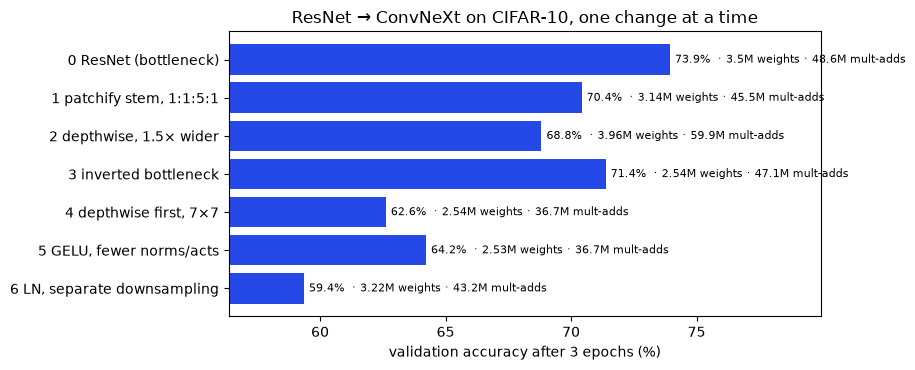

In [34]:
names = list(results)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(names[::-1], [results[n]["val"] for n in names[::-1]], color="#2549e6")
for i, n in enumerate(names[::-1]):
    r = results[n]
    label = f"{r['val']:.1f}%  · {human(r['params'])} weights · {human(r['macs'])} mult-adds"
    ax.text(r["val"] + 0.2, i, label, va="center", fontsize=8)
lo = min(r["val"] for r in results.values())
ax.set_xlim(lo - 3, max(r["val"] for r in results.values()) + 6)
ax.set_xlabel(f"validation accuracy after {LADDER_EPOCHS} epochs (%)")
ax.set_title("ResNet → ConvNeXt on CIFAR-10, one change at a time")
plt.tight_layout()
plt.show()

TODO: the conclusion, after a full 15-epoch run of the ladder on a GPU.

## 7. Try it

1. **Layer scale and stochastic depth.** Real ConvNeXt multiplies `F(x)` by a learned
   per-channel scale initialized at 1e-6, and drops whole blocks at random during
   training. Add both to `Block` (a `micro`-only feature) and rerun step 6.
2. **Is LN the reason?** Rerun step 6 with `norm="bn"`. Does LN help at this scale, or does
   it just get rid of the pitfalls of section 4?
3. **A 7×7 kernel on a 2×2 map.** The last stage runs at 2×2, where a 7×7 kernel is
   mostly padding. Make `kernel` a per-stage tuple, try `(7, 7, 3, 3)`, and compare
   weights and accuracy.
4. **Squeeze-and-excitation.** After the k×k conv, pool to 1×1, go through
   two 1×1 convs (C → C/4 → C) and a sigmoid, and multiply the feature map by the result.
   Add it to step 3 (the MobileNetV3 block).
5. **Is it real?** Two neighbouring steps of the ladder differ by a few tenths of a
   percent. Rerun them with three seeds each. Which differences survive?
6. **Run the ladder properly.** Move `Spec`, `Block` and `LadderNet` into `src/models.py`,
   add one overlay per step in `configs/experiments/`, and train them on Snellius for 100
   epochs.